In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms, models
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# set random seed
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# check gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu128
Device: cuda


## 2. Data preparation

The MRI images are grouped into two classes: Tumor and No Tumor.

The data is split into development (80%) and test (20%) sets.
Only 40% of the development set is used for training and validation.

Exact duplicates are removed before splitting to reduce data leakage.

In [2]:
# dataset path
data_path = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"

print(os.listdir(data_path))

['Testing', 'Training']


In [3]:
# load image paths and labels
data = []

for folder in ["Training", "Testing"]:
    folder_path = os.path.join(data_path, folder)

    for category in os.listdir(folder_path):
        category_path = os.path.join(folder_path, category)

        if not os.path.isdir(category_path):
            continue

        label = 0 if category.lower().replace(" ", "").replace("_", "") == "notumor" else 1

        for filename in os.listdir(category_path):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                data.append({
                    "path": os.path.join(category_path, filename),
                    "label": label,
                    "category": category
                })

df = pd.DataFrame(data)

print("Total images:", len(df))
print(df["category"].value_counts())
print(df["label"].value_counts())

Total images: 7200
category
glioma        1800
meningioma    1800
notumor       1800
pituitary     1800
Name: count, dtype: int64
label
1    5400
0    1800
Name: count, dtype: int64


In [4]:
# calculate image hashes
import hashlib

def image_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

df["hash"] = df["path"].apply(image_hash)

# remove exact duplicates
duplicates = df["hash"].duplicated().sum()
df = df.drop_duplicates(subset="hash").reset_index(drop=True)

print("Exact duplicates removed:", duplicates)
print("Remaining images:", len(df))

Exact duplicates removed: 187
Remaining images: 7013


In [5]:
# split development and test data
dev_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=seed
)

# select 40% of development data
limited_df, _ = train_test_split(
    dev_df,
    train_size=0.40,
    stratify=dev_df["label"],
    random_state=seed
)

# split training and validation data
train_df, val_df = train_test_split(
    limited_df,
    test_size=0.20,
    stratify=limited_df["label"],
    random_state=seed
)

print("Development:", len(dev_df))
print("Limited subset:", len(limited_df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Development: 5610
Limited subset: 2244
Training: 1795
Validation: 449
Test: 1403


### Data leakage check

The training, validation, and test sets are checked for overlapping images.

The GAN is trained only on the real training set.
Validation and test images are not used for GAN training.

In [6]:
# check overlap between datasets
train_hashes = set(train_df["hash"])
val_hashes = set(val_df["hash"])
test_hashes = set(test_df["hash"])

print("Train-Val overlap:", len(train_hashes & val_hashes))
print("Train-Test overlap:", len(train_hashes & test_hashes))
print("Val-Test overlap:", len(val_hashes & test_hashes))

# verify no exact duplicates
assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

print("No exact duplicate leakage detected")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
No exact duplicate leakage detected


            No Tumor  Tumor
Training        1365    430
Validation       341    108
Test            1067    336


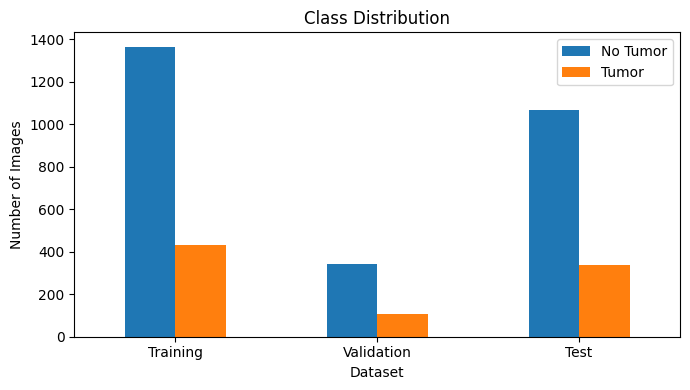

In [7]:
# check class distribution
split_counts = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).T

split_counts.columns = ["No Tumor", "Tumor"]

print(split_counts)

split_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Class Distribution")
plt.xlabel("Dataset")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Image preprocessing

Images are resized to 64×64 for cDCGAN and 224×224 for ResNet50.
Different normalization methods are used for the two models.

In [8]:
# transforms for gan
gan_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# transforms for resnet50
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [9]:
# dataset class
class BrainDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        image = self.transform(image)

        label = int(row["label"])

        return image, label

In [10]:
# create datasets
gan_dataset = BrainDataset(train_df, gan_transform)

train_dataset = BrainDataset(train_df, resnet_transform)
val_dataset = BrainDataset(val_df, resnet_transform)
test_dataset = BrainDataset(test_df, resnet_transform)

# create dataloaders
gan_loader = DataLoader(gan_dataset, batch_size=64, shuffle=True)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("GAN batches:", len(gan_loader))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

GAN batches: 29
Train batches: 57
Validation batches: 15
Test batches: 44


## 4. cDCGAN

A conditional DCGAN is used to generate MRI images for both classes.
The generator creates images based on random noise and class labels.
The discriminator learns to distinguish real and generated images.

In [11]:
# generator
class Generator(nn.Module):
    def __init__(self, nz=100, num_classes=2):
        super().__init__()

        self.label_emb = nn.Embedding(num_classes, nz)

        self.model = nn.Sequential(
            nn.ConvTranspose2d(nz * 2, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_input = self.label_emb(labels).unsqueeze(2).unsqueeze(3)
        x = torch.cat([noise, label_input], dim=1)
        return self.model(x)

In [12]:
# discriminator
class Discriminator(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.label_emb = nn.Embedding(num_classes, 64 * 64)

        self.model = nn.Sequential(
            nn.Conv2d(4, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, images, labels):
        label_input = self.label_emb(labels)
        label_input = label_input.view(-1, 1, 64, 64)

        x = torch.cat([images, label_input], dim=1)

        return self.model(x).view(-1)

In [13]:
# initialize models
G = Generator().to(device)
D = Discriminator().to(device)

# loss and optimizers
criterion = nn.BCELoss()

optimizer_G = torch.optim.Adam(
    G.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

optimizer_D = torch.optim.Adam(
    D.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

print("Generator parameters:", sum(p.numel() for p in G.parameters()))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters()))

Generator parameters: 4396104
Discriminator parameters: 2774784


## 5. GAN training

The cDCGAN is trained using the limited real training set.
Generator and discriminator losses are recorded during training.

In [14]:
# training settings
epochs = 50
nz = 100

g_losses = []
d_losses = []

# fixed noise for sample images
fixed_noise = torch.randn(16, nz, 1, 1, device=device)
fixed_labels = torch.tensor([0] * 8 + [1] * 8, device=device)

for epoch in range(epochs):
    G.train()
    D.train()

    g_loss_total = 0
    d_loss_total = 0

    for real_images, labels in gan_loader:
        real_images = real_images.to(device)
        labels = labels.to(device)

        batch_size = real_images.size(0)

        real_targets = torch.ones(batch_size, device=device)
        fake_targets = torch.zeros(batch_size, device=device)

        # train discriminator
        optimizer_D.zero_grad()

        real_output = D(real_images, labels)
        d_real_loss = criterion(real_output, real_targets)

        noise = torch.randn(batch_size, nz, 1, 1, device=device)
        fake_images = G(noise, labels)

        fake_output = D(fake_images.detach(), labels)
        d_fake_loss = criterion(fake_output, fake_targets)

        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        optimizer_D.step()

        # train generator
        optimizer_G.zero_grad()

        fake_output = D(fake_images, labels)
        g_loss = criterion(fake_output, real_targets)

        g_loss.backward()
        optimizer_G.step()

        g_loss_total += g_loss.item()
        d_loss_total += d_loss.item()

    avg_g_loss = g_loss_total / len(gan_loader)
    avg_d_loss = d_loss_total / len(gan_loader)

    g_losses.append(avg_g_loss)
    d_losses.append(avg_d_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"G Loss: {avg_g_loss:.4f} "
        f"D Loss: {avg_d_loss:.4f}"
    )

Epoch [1/50] G Loss: 6.0998 D Loss: 0.4943
Epoch [2/50] G Loss: 6.7421 D Loss: 0.9833
Epoch [3/50] G Loss: 3.6143 D Loss: 1.4536
Epoch [4/50] G Loss: 2.3069 D Loss: 1.3350
Epoch [5/50] G Loss: 2.9824 D Loss: 0.8674
Epoch [6/50] G Loss: 2.3259 D Loss: 0.9265
Epoch [7/50] G Loss: 3.0401 D Loss: 0.8987
Epoch [8/50] G Loss: 2.6560 D Loss: 0.7651
Epoch [9/50] G Loss: 3.2709 D Loss: 0.7089
Epoch [10/50] G Loss: 3.1327 D Loss: 0.8054
Epoch [11/50] G Loss: 3.0202 D Loss: 0.7268
Epoch [12/50] G Loss: 3.8346 D Loss: 0.5913
Epoch [13/50] G Loss: 3.8494 D Loss: 0.7158
Epoch [14/50] G Loss: 2.9966 D Loss: 0.7097
Epoch [15/50] G Loss: 3.2916 D Loss: 0.5939
Epoch [16/50] G Loss: 4.0416 D Loss: 0.4690
Epoch [17/50] G Loss: 3.9428 D Loss: 0.4127
Epoch [18/50] G Loss: 3.2022 D Loss: 0.7618
Epoch [19/50] G Loss: 2.9127 D Loss: 0.5940
Epoch [20/50] G Loss: 3.2021 D Loss: 0.7013
Epoch [21/50] G Loss: 4.2339 D Loss: 0.5483
Epoch [22/50] G Loss: 3.7333 D Loss: 0.5278
Epoch [23/50] G Loss: 2.5140 D Loss: 0.57

## 6. GAN results

The training losses are plotted to observe the behavior of both networks.
Generated MRI images are displayed to check their visual quality.

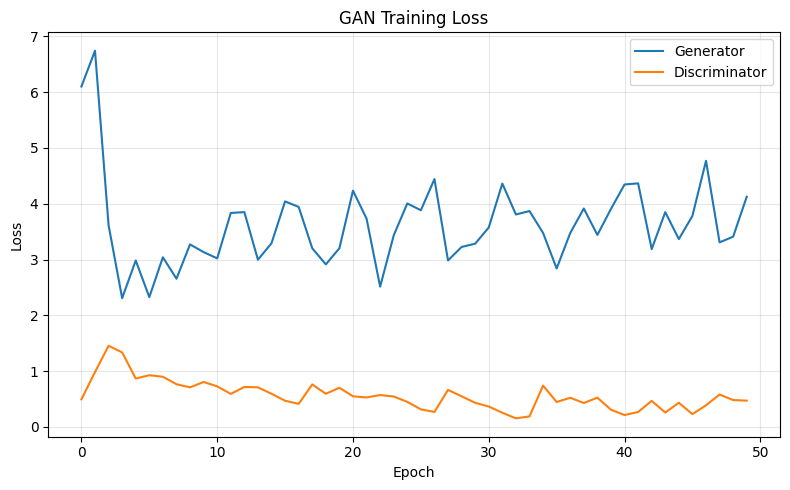

In [15]:
# plot training losses
plt.figure(figsize=(8, 5))

plt.plot(g_losses, label="Generator")
plt.plot(d_losses, label="Discriminator")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

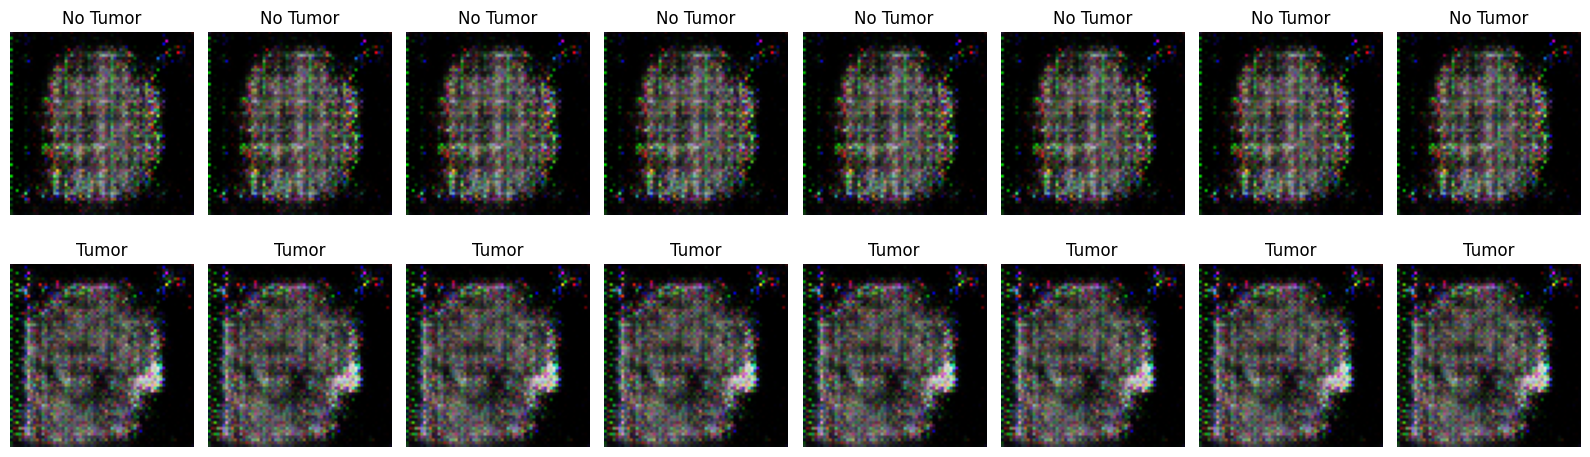

In [16]:
# generate sample images
G.eval()

with torch.no_grad():
    samples = G(fixed_noise, fixed_labels).cpu()

# convert images to [0,1]
samples = (samples + 1) / 2

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i, ax in enumerate(axes.flat):
    image = samples[i].permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title("No Tumor" if i < 8 else "Tumor")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# save gan models
torch.save(G.state_dict(), "/kaggle/working/generator.pth")
torch.save(D.state_dict(), "/kaggle/working/discriminator.pth")

print("Models saved")

Models saved


In [18]:
# save loss history
loss_df = pd.DataFrame({
    "epoch": range(1, epochs + 1),
    "generator_loss": g_losses,
    "discriminator_loss": d_losses
})

loss_df.to_csv("/kaggle/working/gan_losses.csv", index=False)

print("Training results saved")

Training results saved


## 7. FID evaluation

FID is used to compare real and generated MRI images.
A lower FID score indicates that the generated images are closer
to real images in the feature space.

In [19]:
# install fid metric
!pip -q install torchmetrics[image] torch-fidelity

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 2.1 MB/s eta 0:00:00a 0:00:01


In [20]:
from torchmetrics.image.fid import FrechetInceptionDistance

# initialize fid
fid = FrechetInceptionDistance(
    feature=2048,
    normalize=True
).to(device)

G.eval()

# load real training images
real_dataset = BrainDataset(train_df, gan_transform)
real_loader = DataLoader(
    real_dataset,
    batch_size=32,
    shuffle=False
)

# add real images
with torch.no_grad():
    for images, _ in real_loader:
        images = ((images.to(device) + 1) / 2).clamp(0, 1)
        fid.update(images, real=True)

# match real class distribution
class_counts = train_df["label"].value_counts().sort_index()

# generate synthetic images
with torch.no_grad():
    for label, count in class_counts.items():
        generated = 0

        while generated < count:
            batch_size = min(32, count - generated)

            noise = torch.randn(
                batch_size, 100, 1, 1,
                device=device
            )

            labels = torch.full(
                (batch_size,),
                int(label),
                dtype=torch.long,
                device=device
            )

            fake_images = G(noise, labels)
            fake_images = ((fake_images + 1) / 2).clamp(0, 1)

            fid.update(fake_images, real=False)

            generated += batch_size

# calculate fid
fid_score = fid.compute().item()

print(f"FID Score: {fid_score:.2f}")

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 224MB/s] 


FID Score: 348.40


In [21]:
# save fid result
fid_df = pd.DataFrame({
    "metric": ["FID"],
    "score": [fid_score]
})

fid_df.to_csv("/kaggle/working/fid_result.csv", index=False)

print("FID result saved")

FID result saved


## 8. ResNet50 baseline

ResNet50 is trained using only real MRI images from the limited training set.

The model is evaluated on the validation set during training. The final performance is measured on the independent test set.

In [22]:
# load pretrained resnet50
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# replace classification layer
model.fc = nn.Linear(model.fc.in_features, 2)

model = model.to(device)

# loss and optimizer
criterion_cls = nn.CrossEntropyLoss()

optimizer_cls = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("ResNet50 ready")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 154MB/s] 


ResNet50 ready


In [23]:
# training settings
epochs_cls = 10

train_losses = []
val_losses = []
train_accs = []
val_accs = []

best_val_acc = 0.0

for epoch in range(epochs_cls):

    # training
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_cls.zero_grad()

        outputs = model(images)
        loss = criterion_cls(outputs, labels)

        loss.backward()
        optimizer_cls.step()

        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # validation
    model.eval()

    running_val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion_cls(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss = running_val_loss / val_total
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    # save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "/kaggle/working/resnet50_baseline.pth"
        )

    print(
        f"Epoch [{epoch+1}/{epochs_cls}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch [1/10] Train Loss: 0.1757 Val Loss: 0.0718 Train Acc: 0.9365 Val Acc: 0.9733
Epoch [2/10] Train Loss: 0.0309 Val Loss: 0.1634 Train Acc: 0.9922 Val Acc: 0.9755
Epoch [3/10] Train Loss: 0.0098 Val Loss: 0.1737 Train Acc: 0.9983 Val Acc: 0.9800
Epoch [4/10] Train Loss: 0.0192 Val Loss: 0.0400 Train Acc: 0.9955 Val Acc: 0.9911
Epoch [5/10] Train Loss: 0.0027 Val Loss: 0.0852 Train Acc: 0.9994 Val Acc: 0.9822
Epoch [6/10] Train Loss: 0.0017 Val Loss: 0.0413 Train Acc: 1.0000 Val Acc: 0.9911
Epoch [7/10] Train Loss: 0.0017 Val Loss: 0.0467 Train Acc: 1.0000 Val Acc: 0.9911
Epoch [8/10] Train Loss: 0.0010 Val Loss: 0.0337 Train Acc: 1.0000 Val Acc: 0.9911
Epoch [9/10] Train Loss: 0.0164 Val Loss: 0.0483 Train Acc: 0.9939 Val Acc: 0.9866
Epoch [10/10] Train Loss: 0.0049 Val Loss: 0.0336 Train Acc: 0.9989 Val Acc: 0.9889


## 9. Baseline results

Training and validation results are visualized to check model performance and possible overfitting.

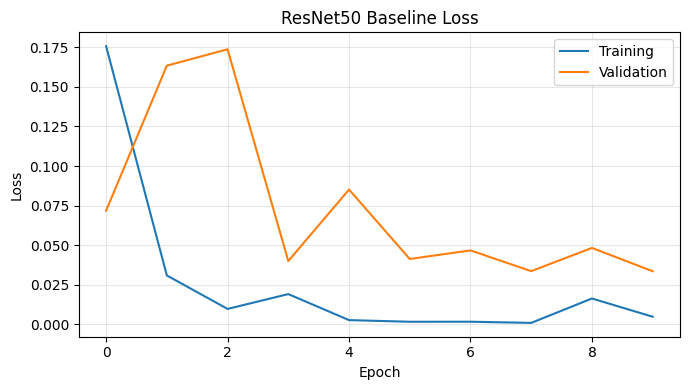

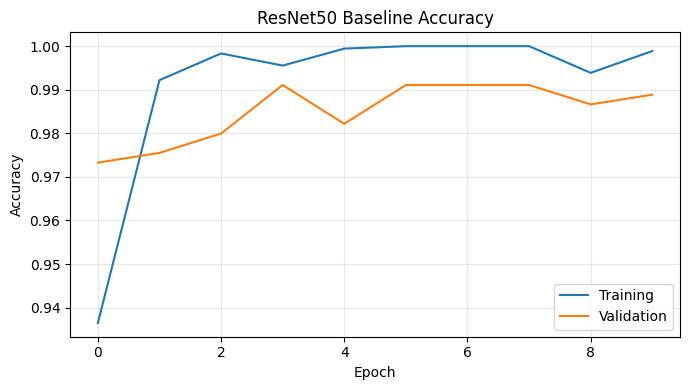

In [24]:
# plot loss
plt.figure(figsize=(7, 4))

plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Baseline Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# plot accuracy
plt.figure(figsize=(7, 4))

plt.plot(train_accs, label="Training")
plt.plot(val_accs, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Baseline Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# load best baseline model
model.load_state_dict(
    torch.load(
        "/kaggle/working/resnet50_baseline.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

# evaluate on real test images
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# calculate metrics
baseline_results = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1-score": f1_score(y_true, y_pred, zero_division=0)
}

print("Baseline Results")

for metric, value in baseline_results.items():
    print(f"{metric}: {value:.4f}")

Baseline Results
Accuracy: 0.9808
Precision: 0.9887
Recall: 0.9859
F1-score: 0.9873


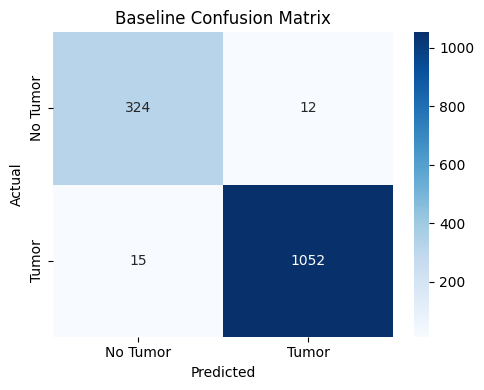

In [26]:
# plot confusion matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Tumor", "Tumor"],
    yticklabels=["No Tumor", "Tumor"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline Confusion Matrix")

plt.tight_layout()
plt.show()

In [27]:
# save baseline metrics
baseline_df = pd.DataFrame([baseline_results])
baseline_df.insert(0, "Model", "Real Only")

baseline_df.to_csv(
    "/kaggle/working/baseline_results.csv",
    index=False
)

print(baseline_df)

       Model  Accuracy  Precision    Recall  F1-score
0  Real Only  0.980756   0.988722  0.985942   0.98733


## 10. Data augmentation

Synthetic MRI images are generated using the trained cDCGAN.

The generated images are added only to the training set. Validation and test sets remain unchanged.

The number of synthetic images is equal to the number of real training images.

In [28]:
# generate synthetic images
import os

synthetic_dir = "/kaggle/working/synthetic_mri"
os.makedirs(synthetic_dir, exist_ok=True)

G.eval()

synthetic_data = []

class_counts = train_df["label"].value_counts().sort_index()

with torch.no_grad():
    for label, count in class_counts.items():
        generated = 0

        while generated < count:
            batch_size = min(32, count - generated)

            noise = torch.randn(batch_size, 100, 1, 1, device=device)
            labels = torch.full(
                (batch_size,), int(label),
                dtype=torch.long,
                device=device
            )

            fake_images = G(noise, labels)

            for i, image in enumerate(fake_images):
                filename = f"class_{label}_{generated + i}.png"
                path = os.path.join(synthetic_dir, filename)

                torchvision.utils.save_image(
                    image,
                    path,
                    normalize=True,
                    value_range=(-1, 1)
                )

                synthetic_data.append({
                    "path": path,
                    "label": int(label)
                })

            generated += batch_size

synthetic_df = pd.DataFrame(synthetic_data)

print("Synthetic images:", len(synthetic_df))
print(synthetic_df["label"].value_counts())

Synthetic images: 1795
label
1    1365
0     430
Name: count, dtype: int64


In [29]:
# combine real and synthetic images
augmented_train_df = pd.concat(
    [train_df[["path", "label"]], synthetic_df],
    ignore_index=True
)

print("Real images:", len(train_df))
print("Synthetic images:", len(synthetic_df))
print("Total training images:", len(augmented_train_df))

Real images: 1795
Synthetic images: 1795
Total training images: 3590


In [30]:
# create augmented dataloader
augmented_dataset = BrainDataset(
    augmented_train_df,
    resnet_transform
)

augmented_loader = DataLoader(
    augmented_dataset,
    batch_size=32,
    shuffle=True
)

print("Augmented batches:", len(augmented_loader))

Augmented batches: 113


## 11. ResNet50 with augmentation

A second ResNet50 is trained using real and synthetic MRI images.

The same architecture, optimizer, learning rate, and number of epochs are used as in the baseline experiment.

In [31]:
# initialize resnet50
aug_model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

aug_model.fc = nn.Linear(aug_model.fc.in_features, 2)
aug_model = aug_model.to(device)

# loss and optimizer
criterion_aug = nn.CrossEntropyLoss()

optimizer_aug = torch.optim.Adam(
    aug_model.parameters(),
    lr=0.0001
)

In [32]:
# training history
aug_train_losses = []
aug_val_losses = []
aug_train_accs = []
aug_val_accs = []

best_aug_val_acc = -1.0

for epoch in range(epochs_cls):

    # training
    aug_model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in augmented_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_aug.zero_grad()

        outputs = aug_model(images)
        loss = criterion_aug(outputs, labels)

        loss.backward()
        optimizer_aug.step()

        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # validation
    aug_model.eval()

    running_val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_model(images)
            loss = criterion_aug(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss = running_val_loss / val_total
    val_acc = val_correct / val_total

    aug_train_losses.append(train_loss)
    aug_val_losses.append(val_loss)

    aug_train_accs.append(train_acc)
    aug_val_accs.append(val_acc)

    # save best model
    if val_acc > best_aug_val_acc:
        best_aug_val_acc = val_acc

        torch.save(
            aug_model.state_dict(),
            "/kaggle/working/resnet50_augmented.pth"
        )

    print(
        f"Epoch [{epoch+1}/{epochs_cls}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch [1/10] Train Loss: 0.0823 Val Loss: 0.0659 Train Acc: 0.9741 Val Acc: 0.9710
Epoch [2/10] Train Loss: 0.0170 Val Loss: 0.0380 Train Acc: 0.9947 Val Acc: 0.9889
Epoch [3/10] Train Loss: 0.0097 Val Loss: 0.0392 Train Acc: 0.9969 Val Acc: 0.9866
Epoch [4/10] Train Loss: 0.0064 Val Loss: 0.0502 Train Acc: 0.9986 Val Acc: 0.9866
Epoch [5/10] Train Loss: 0.0055 Val Loss: 0.0262 Train Acc: 0.9986 Val Acc: 0.9933
Epoch [6/10] Train Loss: 0.0022 Val Loss: 0.0337 Train Acc: 0.9997 Val Acc: 0.9844
Epoch [7/10] Train Loss: 0.0024 Val Loss: 0.0391 Train Acc: 0.9989 Val Acc: 0.9889
Epoch [8/10] Train Loss: 0.0003 Val Loss: 0.0270 Train Acc: 1.0000 Val Acc: 0.9933
Epoch [9/10] Train Loss: 0.0012 Val Loss: 0.0236 Train Acc: 0.9997 Val Acc: 0.9955
Epoch [10/10] Train Loss: 0.0099 Val Loss: 0.0527 Train Acc: 0.9972 Val Acc: 0.9866


## 12. Augmented model results

Training and validation results are plotted to observe model performance.

The best model is evaluated on the same real test set used for the baseline.

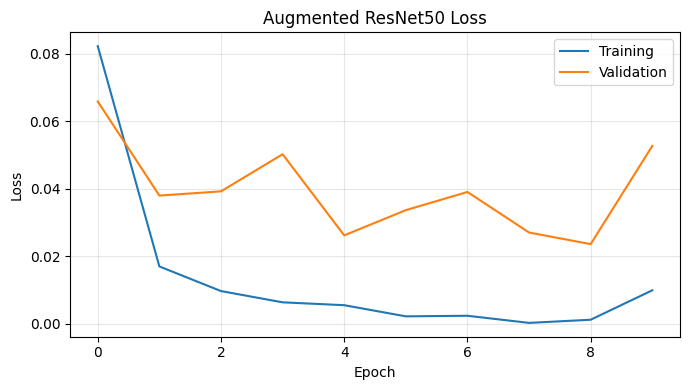

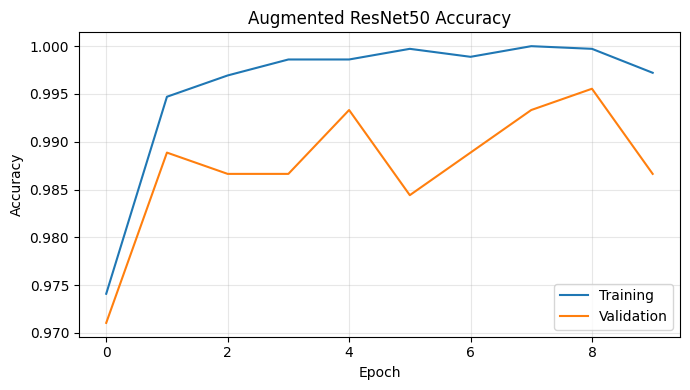

In [33]:
# plot loss
plt.figure(figsize=(7, 4))

plt.plot(aug_train_losses, label="Training")
plt.plot(aug_val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Augmented ResNet50 Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# plot accuracy
plt.figure(figsize=(7, 4))

plt.plot(aug_train_accs, label="Training")
plt.plot(aug_val_accs, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Augmented ResNet50 Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
# load best augmented model
aug_model.load_state_dict(
    torch.load(
        "/kaggle/working/resnet50_augmented.pth",
        map_location=device,
        weights_only=True
    )
)

aug_model.eval()

aug_y_true = []
aug_y_pred = []

# evaluate on real test images
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = aug_model(images)
        predictions = outputs.argmax(dim=1)

        aug_y_true.extend(labels.numpy())
        aug_y_pred.extend(predictions.cpu().numpy())

# calculate metrics
augmented_results = {
    "Accuracy": accuracy_score(aug_y_true, aug_y_pred),
    "Precision": precision_score(aug_y_true, aug_y_pred, zero_division=0),
    "Recall": recall_score(aug_y_true, aug_y_pred, zero_division=0),
    "F1-score": f1_score(aug_y_true, aug_y_pred, zero_division=0)
}

print("Augmented Results")

for metric, value in augmented_results.items():
    print(f"{metric}: {value:.4f}")

Augmented Results
Accuracy: 0.9922
Precision: 0.9981
Recall: 0.9916
F1-score: 0.9948


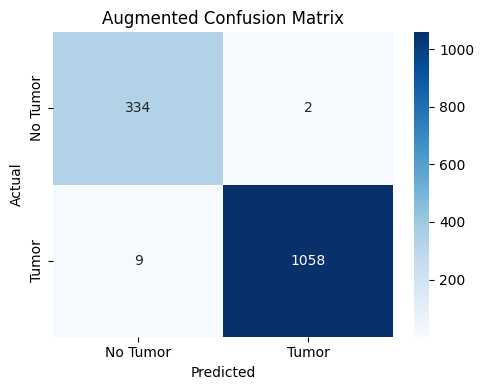

In [35]:
# plot confusion matrix
cm_aug = confusion_matrix(
    aug_y_true,
    aug_y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_aug,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Tumor", "Tumor"],
    yticklabels=["No Tumor", "Tumor"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Augmented Confusion Matrix")

plt.tight_layout()
plt.show()

## 13. Comparison

The baseline and augmented models are compared using accuracy, precision, recall, and F1-score.

Both models are evaluated on the same real test images.

In [36]:
# compare model results
comparison_df = pd.DataFrame(
    [baseline_results, augmented_results],
    index=["Real Only", "Real + Synthetic"]
)

print(comparison_df.round(4))

                  Accuracy  Precision  Recall  F1-score
Real Only           0.9808     0.9887  0.9859    0.9873
Real + Synthetic    0.9922     0.9981  0.9916    0.9948


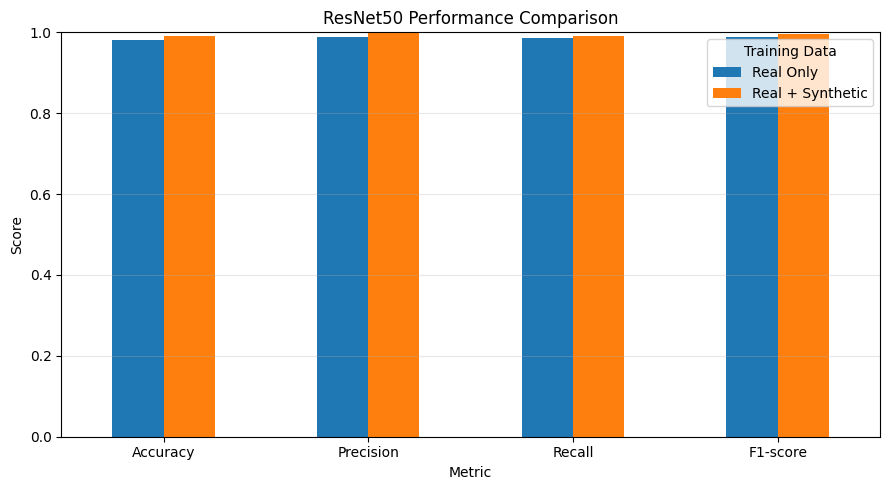

In [37]:
# plot model comparison
comparison_df.T.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("ResNet50 Performance Comparison")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Training Data")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# calculate performance difference
difference = (
    comparison_df.loc["Real + Synthetic"]
    - comparison_df.loc["Real Only"]
) * 100

print("Performance Difference (percentage points)")

for metric, value in difference.items():
    print(f"{metric}: {value:+.2f}")

Performance Difference (percentage points)
Accuracy: +1.14
Precision: +0.94
Recall: +0.56
F1-score: +0.75


In [39]:
# save comparison results
comparison_df.to_csv(
    "/kaggle/working/model_comparison.csv"
)

print("Comparison saved")

Comparison saved
